# Tugas - Medical Cost Prediction

| Nama | NRP |
|------|-----|
| Benedictus Ryu Gunawan | 5054251001 |

## Deskripsi Tugas

Pada tugas ini, kita akan menggunakan Medical Cost Personal Dataset dari Kaggle.

Dataset:
- https://www.kaggle.com/mirichoi0218/insurance

Target yang diprediksi adalah `charges`.

Model yang digunakan:
1. Linear Regression
2. Polynomial Regression
3. Ridge Regression
4. Lasso Regression
5. Decision Tree Regressor
6. Support Vector Regression

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
# Import library yang dibutuhkan.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import sys
from pathlib import Path
from dataclasses import dataclass

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, KFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style='whitegrid')
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [2]:
# Load dataset.
# Sesuaikan nama file dengan file dataset yang digunakan.
df = pd.read_csv('data/insurance.csv')

In [3]:
# Tampilkan beberapa baris pertama dataset.
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [4]:
# Tampilkan informasi dataset.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [5]:
# Periksa missing value.
print('Jumlah missing value per kolom:')
display(df.isnull().sum())
print('Total missing value :', df.isnull().sum().sum())
print('Jumlah baris duplikat:', df.duplicated().sum())

Jumlah missing value per kolom:


age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Total missing value : 0
Jumlah baris duplikat: 1


In [6]:
# Tampilkan statistik deskriptif fitur numerik.
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [7]:
# Tampilkan jumlah nilai pada setiap fitur kategorikal.
for col in df.select_dtypes(include=['object', 'category']).columns:
    print(f'\n{col}:')
    print(df[col].value_counts())


sex:
sex
male      676
female    662
Name: count, dtype: int64

smoker:
smoker
no     1064
yes     274
Name: count, dtype: int64

region:
region
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64


## Lakukan Exploratory Data Analysis (EDA) sederhana yang diperlukan.

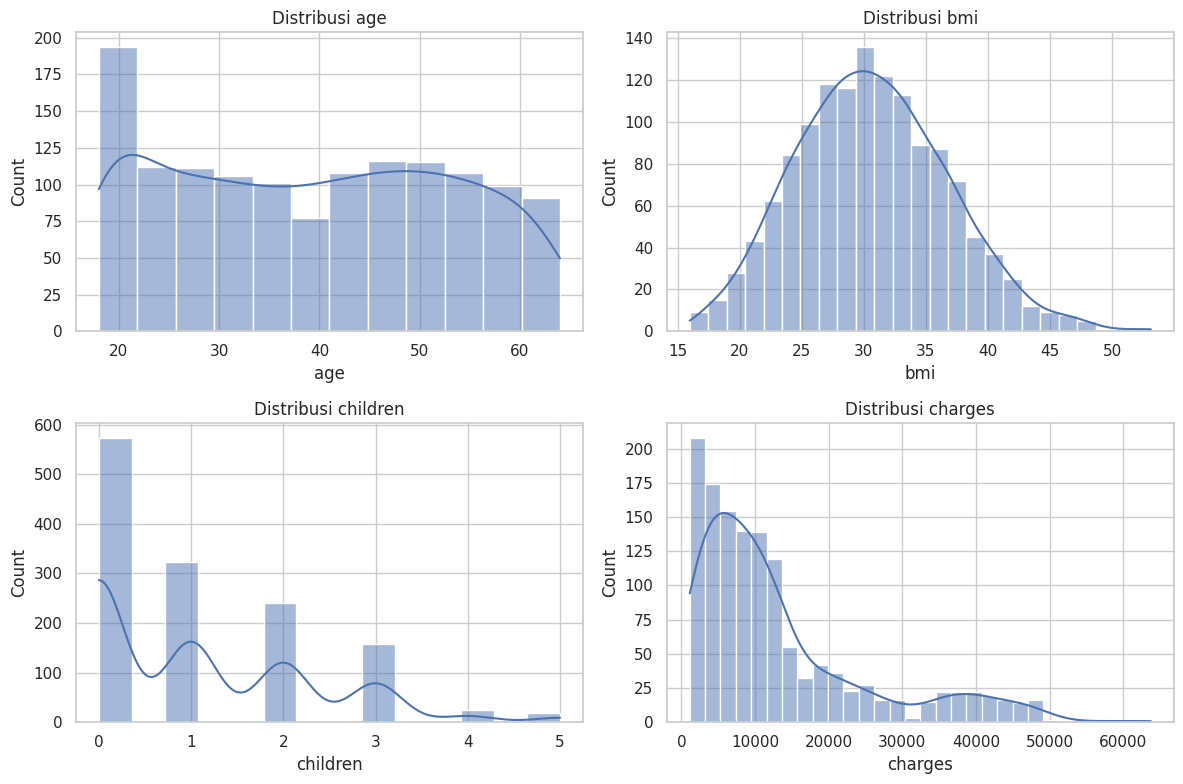

In [8]:
# Distribusi target dan fitur numerik.
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.ravel(), ['age', 'bmi', 'children', 'charges']):
    sns.histplot(df[col], kde=True, ax=ax)
    ax.set_title(f'Distribusi {col}')
plt.tight_layout()
plt.show()

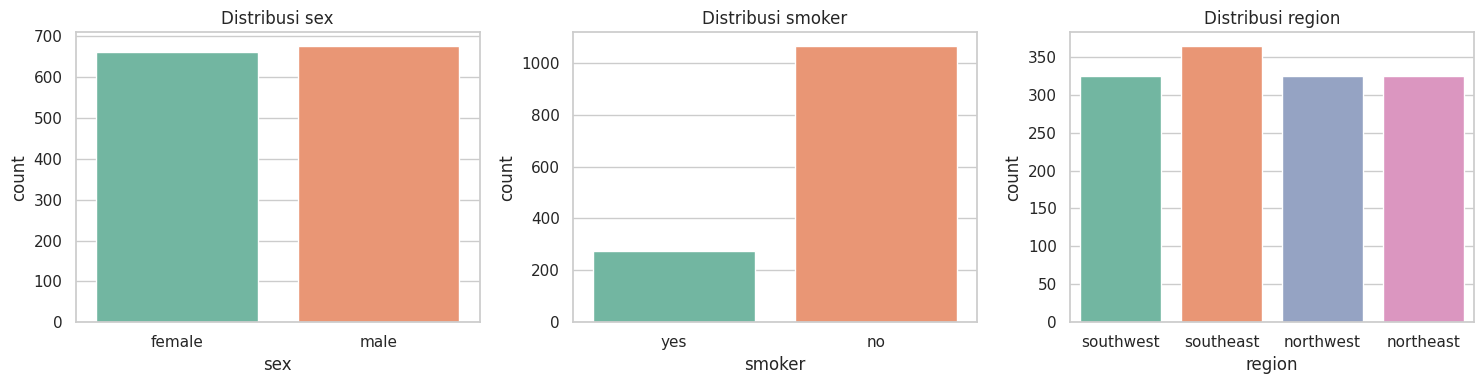

In [9]:
# Distribusi fitur kategorikal.
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ['sex', 'smoker', 'region']):
    sns.countplot(data=df, x=col, hue=col, legend=False, palette='Set2', ax=ax)
    ax.set_title(f'Distribusi {col}')
plt.tight_layout()
plt.show()

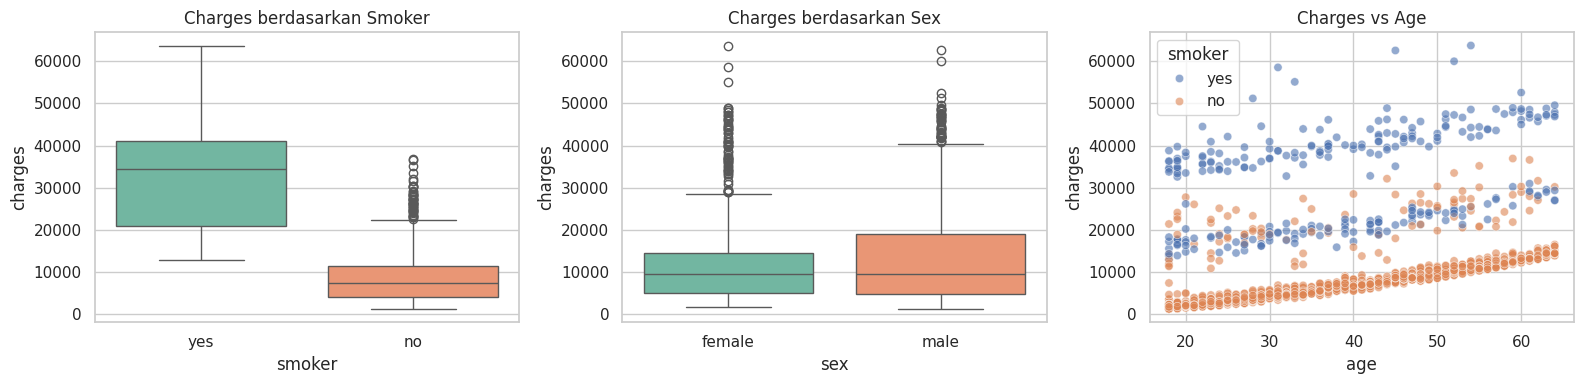

In [10]:
# Hubungan fitur dengan target.
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.boxplot(data=df, x='smoker', y='charges', hue='smoker', legend=False, palette='Set2', ax=axes[0])
axes[0].set_title('Charges berdasarkan Smoker')
sns.boxplot(data=df, x='sex', y='charges', hue='sex', legend=False, palette='Set2', ax=axes[1])
axes[1].set_title('Charges berdasarkan Sex')
sns.scatterplot(data=df, x='age', y='charges', hue='smoker', alpha=0.6, ax=axes[2])
axes[2].set_title('Charges vs Age')
plt.tight_layout()
plt.show()

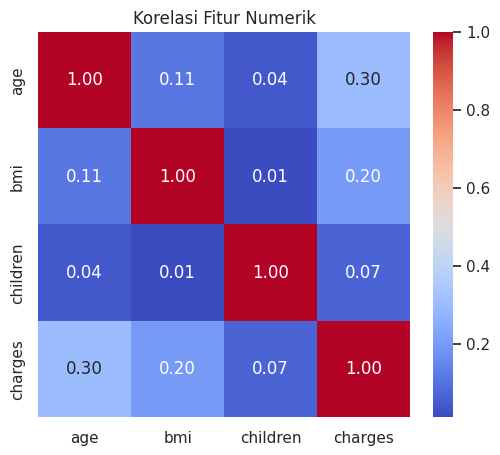

In [11]:
# Korelasi antar fitur numerik.
plt.figure(figsize=(6, 5))
sns.heatmap(df[['age', 'bmi', 'children', 'charges']].corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Korelasi Fitur Numerik')
plt.show()

**Temuan EDA singkat:**

1. Dataset berisi 1.338 baris tanpa missing value (terdapat 1 baris duplikat).
2. Distribusi `charges` *right-skewed* (ekor panjang ke kanan) dan tampak bimodal, mengindikasikan adanya kelompok populasi yang berbeda.
3. `smoker` adalah fitur yang paling membedakan: perokok memiliki `charges` jauh lebih tinggi dan sebaran yang lebih lebar. Ini mengindikasikan adanya interaksi `smoker` dengan fitur lain (misalnya `bmi`).
4. `age` berhubungan positif dengan `charges`, sedangkan `sex` dan `region` tampak tidak terlalu membedakan.

# 2. Preprocessing

Pisahkan fitur numerik dan kategorikal. Gunakan OneHotEncoder untuk fitur kategorikal.

Model Linear Regression, Polynomial Regression, Ridge, Lasso, dan SVR menggunakan data yang telah di-scaling. Decision Tree Regressor tidak memerlukan scaling.

In [12]:
# Pisahkan fitur (X) dan target (y).
TARGET = 'charges'
X = df.drop(columns=[TARGET])
y = df[TARGET]

print('Shape X:', X.shape)
print('Shape y:', y.shape)

Shape X: (1338, 6)
Shape y: (1338,)


In [13]:
# Identifikasi kolom numerik dan kategorikal.
numerical_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()

print('Fitur numerik   :', numerical_cols)
print('Fitur kategorikal:', categorical_cols)

Fitur numerik   : ['age', 'bmi', 'children']
Fitur kategorikal: ['sex', 'smoker', 'region']


In [14]:
# Bagi data menjadi train set dan test set.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

print('Jumlah data train:', X_train.shape[0])
print('Jumlah data test :', X_test.shape[0])

Jumlah data train: 1070
Jumlah data test : 268


In [15]:
# Buat preprocessing untuk fitur numerik dan kategorikal.
# 1. Dengan scaling -> untuk model linear, Polynomial, Ridge, Lasso, dan SVR.
preprocessor_scaled = ColumnTransformer([
    ('num', StandardScaler(), numerical_cols),
    ('cat', OneHotEncoder(drop='first'), categorical_cols),
])

# 2. Tanpa scaling -> untuk Decision Tree (split berbasis threshold, tidak terpengaruh skala).
preprocessor_unscaled = ColumnTransformer([
    ('num', 'passthrough', numerical_cols),
    ('cat', OneHotEncoder(drop='first'), categorical_cols),
])

**Catatan preprocessing:**

- `StandardScaler` menstandarisasi fitur numerik (`age`, `bmi`, `children`) agar memiliki mean 0 dan standar deviasi 1. Ini penting untuk model berbasis jarak/gradien seperti SVR dan membuat penalti regularisasi Ridge/Lasso adil untuk semua fitur.
- `OneHotEncoder(drop='first')` mengubah fitur kategorikal menjadi dummy variable dan membuang satu kategori sebagai referensi untuk menghindari *dummy variable trap* (multikolinearitas sempurna).
- Decision Tree tidak memerlukan scaling karena split hanya membandingkan threshold per fitur, sehingga hasilnya invarian terhadap transformasi monotonik.

# 3. Eksperimen Model

## 3.1 Linear Regression

Bangun model Linear Regression menggunakan data hasil preprocessing.

In [16]:
# Inisialisasi dan latih Linear Regression.
model_lr = Pipeline([
    ('preprocessor', preprocessor_scaled),
    ('model', LinearRegression()),
])
model_lr.fit(X_train, y_train)

print('Intercept        :', model_lr.named_steps['model'].intercept_)
print('R2 pada data train:', model_lr.score(X_train, y_train))

Intercept        : 8955.244801502886
R2 pada data train: 0.7417255854683333


In [17]:
# Lakukan prediksi pada test set.
y_pred_lr = model_lr.predict(X_test)

## 3.2 Polynomial Regression

Gunakan PolynomialFeatures. Tentukan degree berdasarkan eksperimen.

In [18]:
# Buat fitur polynomial dan latih model.
# Eksperimen degree (1-4) untuk memilih nilai terbaik berdasarkan CV RMSE.
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

degree_results = []
for degree in [1, 2, 3, 4]:
    pipe = Pipeline([
        ('preprocessor', preprocessor_scaled),
        ('poly', PolynomialFeatures(degree=degree, include_bias=False)),
        ('model', LinearRegression()),
    ])
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='neg_root_mean_squared_error')
    degree_results.append({'Degree': degree, 'CV RMSE': (-scores).mean()})

degree_results = pd.DataFrame(degree_results)
display(degree_results)

best_degree = int(degree_results.loc[degree_results['CV RMSE'].idxmin(), 'Degree'])
print('Degree terbaik berdasarkan CV:', best_degree)

model_poly = Pipeline([
    ('preprocessor', preprocessor_scaled),
    ('poly', PolynomialFeatures(degree=best_degree, include_bias=False)),
    ('model', LinearRegression()),
])
model_poly.fit(X_train, y_train)

n_features = model_poly.named_steps['poly'].n_output_features_
print('Jumlah fitur setelah PolynomialFeatures:', n_features)

,Degree,CV RMSE
0,1,6123.353823
1,2,4887.276761
2,3,5144.414444
3,4,6469.783417


Degree terbaik berdasarkan CV: 2
Jumlah fitur setelah PolynomialFeatures: 44


In [19]:
# Lakukan prediksi pada test set.
y_pred_poly = model_poly.predict(X_test)

## 3.3 Ridge Regression

Gunakan Ridge Regression. Tentukan nilai alpha berdasarkan eksperimen.

In [20]:
# Inisialisasi dan latih Ridge Regression.
# Eksperimen nilai alpha dengan GridSearchCV (5-fold CV).
param_grid_ridge = {'model__alpha': [0.001, 0.01, 0.1, 1, 10, 100]}

grid_ridge = GridSearchCV(
    Pipeline([
        ('preprocessor', preprocessor_scaled),
        ('model', Ridge(random_state=RANDOM_STATE)),
    ]),
    param_grid_ridge,
    cv=cv,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1,
)
grid_ridge.fit(X_train, y_train)

cv_ridge = pd.DataFrame(grid_ridge.cv_results_)
cv_ridge['CV RMSE'] = -cv_ridge['mean_test_score']
print('Hasil eksperimen alpha:')
display(cv_ridge[['param_model__alpha', 'CV RMSE']].sort_values('param_model__alpha').reset_index(drop=True))

print('Alpha terbaik :', grid_ridge.best_params_['model__alpha'])
print('CV RMSE terbaik:', -grid_ridge.best_score_)

model_ridge = grid_ridge.best_estimator_

ridge_coefs = pd.Series(
    model_ridge.named_steps['model'].coef_,
    index=model_ridge.named_steps['preprocessor'].get_feature_names_out(),
).sort_values(key=abs, ascending=False)
print('\nKoefisien Ridge (diurutkan berdasarkan |koefisien|):')
display(ridge_coefs)

Hasil eksperimen alpha:


,param_model__alpha,CV RMSE
0,0.001,6123.353565
1,0.010,6123.351285
2,0.100,6123.332084
3,1.000,6123.495474
4,10.000,6155.858607
5,100.000,7331.576969


Alpha terbaik : 0.1
CV RMSE terbaik: 6123.332084236481

Koefisien Ridge (diurutkan berdasarkan |koefisien|):


cat__smoker_yes          23637.407996
num__age                  3614.383287
num__bmi                  2035.938458
cat__region_southwest     -809.102123
cat__region_southeast     -656.364805
num__children              516.958152
cat__region_northwest     -370.216573
cat__sex_male              -17.789346
dtype: float64

In [21]:
# Lakukan prediksi pada test set.
y_pred_ridge = model_ridge.predict(X_test)

## 3.4 Lasso Regression

Gunakan Lasso Regression. Tentukan nilai alpha berdasarkan eksperimen.

In [22]:
# Inisialisasi dan latih Lasso Regression.
# Eksperimen nilai alpha dengan GridSearchCV (5-fold CV).
param_grid_lasso = {'model__alpha': [0.001, 0.01, 0.1, 1, 10, 100]}

grid_lasso = GridSearchCV(
    Pipeline([
        ('preprocessor', preprocessor_scaled),
        ('model', Lasso(max_iter=100000, random_state=RANDOM_STATE)),
    ]),
    param_grid_lasso,
    cv=cv,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1,
)
grid_lasso.fit(X_train, y_train)

cv_lasso = pd.DataFrame(grid_lasso.cv_results_)
cv_lasso['CV RMSE'] = -cv_lasso['mean_test_score']
print('Hasil eksperimen alpha:')
display(cv_lasso[['param_model__alpha', 'CV RMSE']].sort_values('param_model__alpha').reset_index(drop=True))

print('Alpha terbaik :', grid_lasso.best_params_['model__alpha'])
print('CV RMSE terbaik:', -grid_lasso.best_score_)

model_lasso = grid_lasso.best_estimator_

lasso_model = model_lasso.named_steps['model']
lasso_coefs = pd.Series(
    lasso_model.coef_,
    index=model_lasso.named_steps['preprocessor'].get_feature_names_out(),
).sort_values(key=abs, ascending=False)
print('Koefisien Lasso (diurutkan berdasarkan |koefisien|):')
display(lasso_coefs)
print('Jumlah koefisien yang menjadi nol:', (lasso_model.coef_ == 0).sum(), 'dari', len(lasso_model.coef_))

Hasil eksperimen alpha:


,param_model__alpha,CV RMSE
0,0.001,6123.353728
1,0.010,6123.352870
2,0.100,6123.344541
3,1.000,6123.265824
4,10.000,6122.789713
5,100.000,6119.852549


Alpha terbaik : 100
CV RMSE terbaik: 6119.852548972322
Koefisien Lasso (diurutkan berdasarkan |koefisien|):


cat__smoker_yes          23030.876641
num__age                  3519.438214
num__bmi                  1888.552090
num__children              428.200788
cat__sex_male                0.000000
cat__region_northwest        0.000000
cat__region_southeast       -0.000000
cat__region_southwest       -0.000000
dtype: float64

Jumlah koefisien yang menjadi nol: 4 dari 8


In [23]:
# Lakukan prediksi pada test set.
y_pred_lasso = model_lasso.predict(X_test)

## 3.5 Decision Tree Regressor

Gunakan Decision Tree Regressor. Eksperimen dapat dilakukan pada `max_depth` dan `min_samples_leaf`.

In [24]:
# Inisialisasi dan latih Decision Tree Regressor.
# Decision Tree tidak memerlukan scaling, sehingga menggunakan preprocessor_unscaled.
param_grid_tree = {
    'model__max_depth': [3, 5, 7, 10, None],
    'model__min_samples_leaf': [1, 5, 10, 20],
}

grid_tree = GridSearchCV(
    Pipeline([
        ('preprocessor', preprocessor_unscaled),
        ('model', DecisionTreeRegressor(random_state=RANDOM_STATE)),
    ]),
    param_grid_tree,
    cv=cv,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1,
)
grid_tree.fit(X_train, y_train)

cv_tree = pd.DataFrame(grid_tree.cv_results_)
cv_tree['CV RMSE'] = -cv_tree['mean_test_score']
print('Hasil eksperimen parameter (diurutkan dari CV RMSE terkecil):')
display(cv_tree[['param_model__max_depth', 'param_model__min_samples_leaf', 'CV RMSE']].sort_values('CV RMSE').reset_index(drop=True))

print('Parameter terbaik :', grid_tree.best_params_)
print('CV RMSE terbaik  :', -grid_tree.best_score_)

model_tree = grid_tree.best_estimator_

Hasil eksperimen parameter (diurutkan dari CV RMSE terkecil):


,param_model__max_depth,param_model__min_samples_leaf,CV RMSE
0,5,20,4609.525837
1,5,10,4636.071729
2,5,5,4706.241356
3,3,1,4717.835218
4,3,20,4717.835218
5,3,10,4717.835218
6,3,5,4717.835218
7,7,20,4731.721304
8,10,20,4737.780747
9,None,20,4737.780747


Parameter terbaik : {'model__max_depth': 5, 'model__min_samples_leaf': 20}
CV RMSE terbaik  : 4609.525836552906


In [25]:
# Lakukan prediksi pada test set.
y_pred_tree = model_tree.predict(X_test)

## 3.6 Support Vector Regression

Gunakan SVR dengan data yang telah di-scaling. Tentukan parameter berdasarkan eksperimen.

In [26]:
# Inisialisasi dan latih SVR.
# SVR sangat sensitif terhadap skala data. Selain fitur, target juga perlu di-scaling
# karena epsilon dan C bekerja pada satuan target.
# Eksperimen singkat: dengan parameter yang sama, tanpa vs dengan scaling target.
svr_experiments = {
    'Tanpa scaling target': Pipeline([
        ('preprocessor', preprocessor_scaled),
        ('model', SVR(kernel='rbf', C=10, epsilon=0.1)),
    ]),
    'Dengan scaling target': Pipeline([
        ('preprocessor', preprocessor_scaled),
        ('model', TransformedTargetRegressor(
            regressor=SVR(kernel='rbf', C=10, epsilon=0.1),
            transformer=StandardScaler(),
        )),
    ]),
}

print('Perbandingan pengaruh scaling target pada SVR (parameter sama):')
for label, pipe in svr_experiments.items():
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='neg_root_mean_squared_error')
    print(f'{label}: CV RMSE = {(-scores).mean():,.2f}')

# Grid search parameter SVR (fitur dan target di-scaling).
param_grid_svr = {
    'model__regressor__kernel': ['rbf'],
    'model__regressor__C': [1, 10, 100],
    'model__regressor__epsilon': [0.01, 0.05, 0.1],
}

grid_svr = GridSearchCV(
    Pipeline([
        ('preprocessor', preprocessor_scaled),
        ('model', TransformedTargetRegressor(
            regressor=SVR(),
            transformer=StandardScaler(),
        )),
    ]),
    param_grid_svr,
    cv=cv,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1,
)
grid_svr.fit(X_train, y_train)

cv_svr = pd.DataFrame(grid_svr.cv_results_)
cv_svr['CV RMSE'] = -cv_svr['mean_test_score']
print('\nHasil eksperimen parameter SVR:')
display(cv_svr[['param_model__regressor__C', 'param_model__regressor__epsilon', 'CV RMSE']].sort_values('CV RMSE').reset_index(drop=True))

print('Parameter terbaik :', grid_svr.best_params_)
print('CV RMSE terbaik  :', -grid_svr.best_score_)

model_svr = grid_svr.best_estimator_

Perbandingan pengaruh scaling target pada SVR (parameter sama):
Tanpa scaling target: CV RMSE = 12,507.66


Dengan scaling target: CV RMSE = 5,060.76



Hasil eksperimen parameter SVR:


,param_model__regressor__C,param_model__regressor__epsilon,CV RMSE
0,1,0.10,4900.115399
1,1,0.05,4955.782196
2,1,0.01,4982.578375
3,10,0.01,5031.501954
4,10,0.10,5060.755267
5,10,0.05,5074.304591
6,100,0.01,5718.118994
7,100,0.05,5780.675328
8,100,0.10,5829.237424


Parameter terbaik : {'model__regressor__C': 1, 'model__regressor__epsilon': 0.1, 'model__regressor__kernel': 'rbf'}
CV RMSE terbaik  : 4900.115399420399


In [27]:
# Lakukan prediksi pada test set.
y_pred_svr = model_svr.predict(X_test)

# 4. Evaluasi Model

In [28]:
# Hitung MAE, MSE, RMSE, dan R² untuk setiap model.
# Sajikan hasil dalam satu tabel perbandingan.
predictions = {
    'Linear Regression': y_pred_lr,
    'Polynomial Regression': y_pred_poly,
    'Ridge Regression': y_pred_ridge,
    'Lasso Regression': y_pred_lasso,
    'Decision Tree': y_pred_tree,
    'SVR': y_pred_svr,
}

results = []
for name, y_pred in predictions.items():
    mse = mean_squared_error(y_test, y_pred)
    results.append({
        'Model': name,
        'MAE': mean_absolute_error(y_test, y_pred),
        'MSE': mse,
        'RMSE': np.sqrt(mse),
        'R2': r2_score(y_test, y_pred),
    })

results_df = pd.DataFrame(results).sort_values('RMSE').reset_index(drop=True)
display(results_df.style.format({
    'MAE': '{:,.2f}',
    'MSE': '{:,.2f}',
    'RMSE': '{:,.2f}',
    'R2': '{:.4f}',
}))

,Model,MAE,MSE,RMSE,R2
0,Decision Tree,"2,616.93","20,304,353.94","4,506.04",0.8692
1,Polynomial Regression,"2,729.50","20,712,805.99","4,551.13",0.8666
2,SVR,"2,543.44","23,697,501.37","4,868.01",0.8474
3,Linear Regression,"4,181.19","33,596,915.85","5,796.28",0.7836
4,Ridge Regression,"4,182.39","33,601,518.32","5,796.68",0.7836
5,Lasso Regression,"4,248.49","34,266,062.50","5,853.72",0.7793


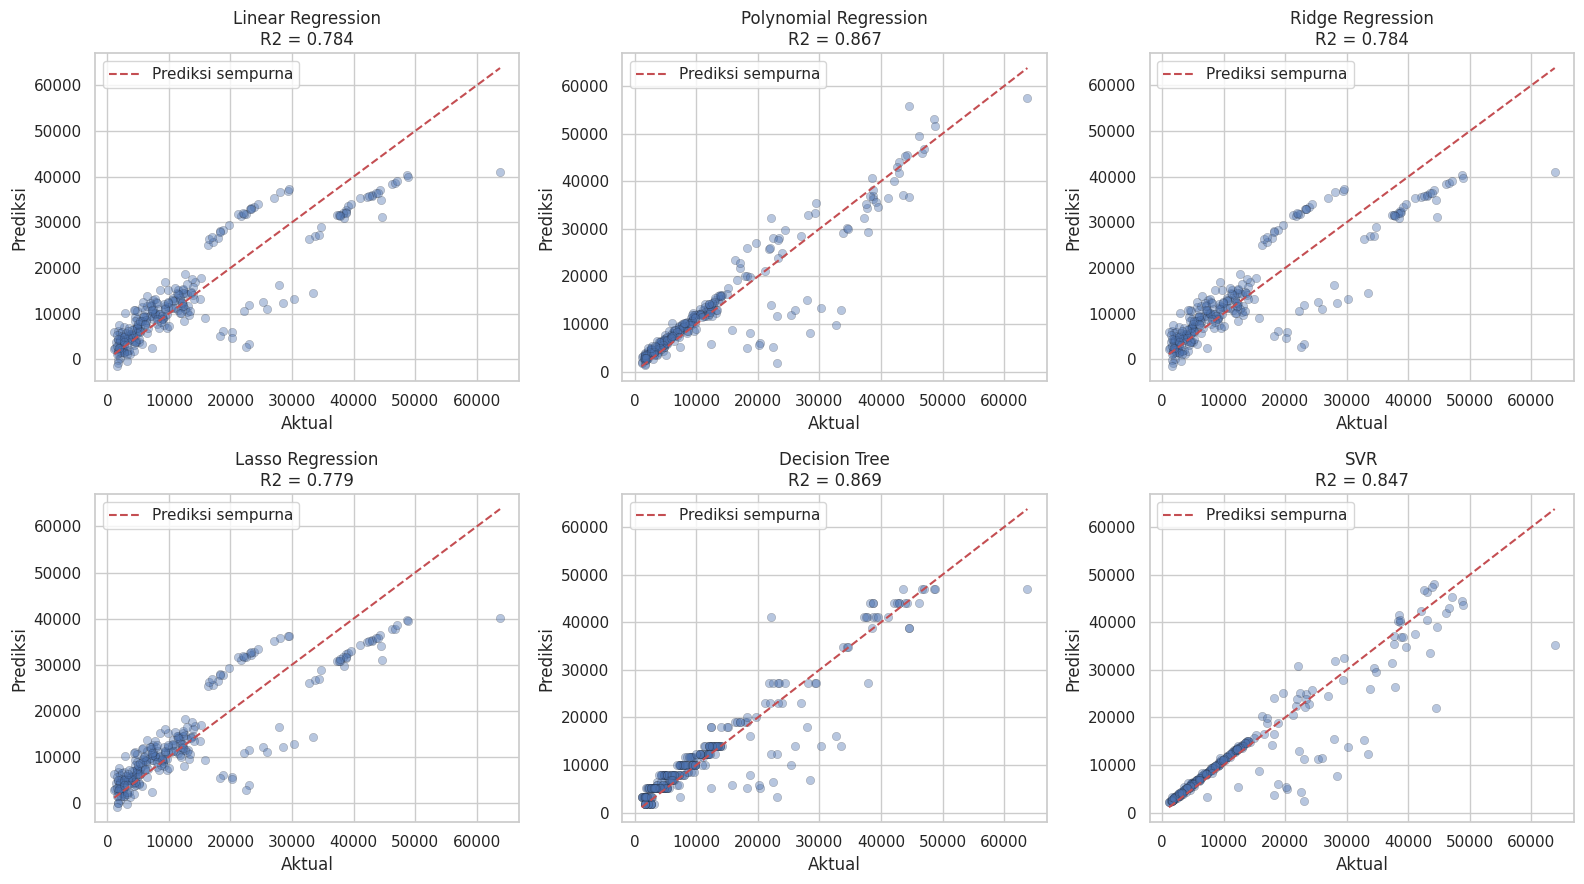

In [29]:
# Buat visualisasi perbandingan nilai aktual dan prediksi jika diperlukan.
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, (name, y_pred) in zip(axes.ravel(), predictions.items()):
    ax.scatter(y_test, y_pred, alpha=0.4, edgecolor='k', linewidth=0.3)
    lim = [y_test.min(), y_test.max()]
    ax.plot(lim, lim, 'r--', label='Prediksi sempurna')
    ax.set_title(f'{name}\nR2 = {r2_score(y_test, y_pred):.3f}')
    ax.set_xlabel('Aktual')
    ax.set_ylabel('Prediksi')
    ax.legend()
plt.tight_layout()
plt.show()

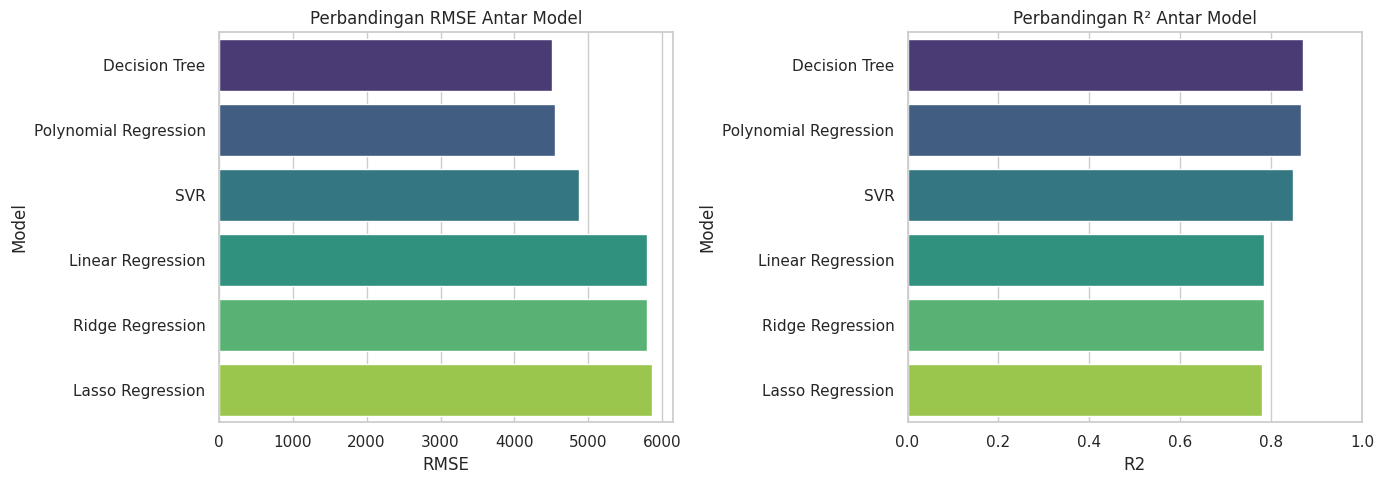

In [30]:
# Perbandingan RMSE dan R² antar model dalam bentuk bar chart.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=results_df, x='RMSE', y='Model', hue='Model', legend=False, palette='viridis', ax=axes[0])
axes[0].set_title('Perbandingan RMSE Antar Model')
sns.barplot(data=results_df, x='R2', y='Model', hue='Model', legend=False, palette='viridis', ax=axes[1])
axes[1].set_title('Perbandingan R² Antar Model')
axes[1].set_xlim(0, 1)
plt.tight_layout()
plt.show()

# 5. Analisis

#### Bandingkan hasil Linear Regression, Polynomial Regression, Ridge, Lasso, Decision Tree Regressor, dan SVR berdasarkan metrik evaluasi. Jelaskan pengaruh preprocessing dan parameter yang digunakan terhadap hasil.

**Ringkasan hasil pada test set (diurutkan berdasarkan RMSE):**

| Peringkat | Model | MAE | RMSE | R² |
|---|---|---|---|---|
| 1 | Decision Tree (`max_depth=5`, `min_samples_leaf=20`) | 2.616,93 | 4.506,04 | 0,8692 |
| 2 | Polynomial Regression (`degree=2`) | 2.729,50 | 4.551,13 | 0,8666 |
| 3 | SVR (`C=1`, `epsilon=0.1`, RBF) | 2.543,44 | 4.868,01 | 0,8474 |
| 4 | Linear Regression | 4.181,19 | 5.796,28 | 0,7836 |
| 5 | Ridge Regression (`alpha=0.1`) | 4.182,39 | 5.796,68 | 0,7836 |
| 6 | Lasso Regression (`alpha=100`) | 4.248,49 | 5.853,72 | 0,7793 |

#### 1. Linear Regression (baseline)
Linear Regression hanya mencapai R² 0,7836 dengan RMSE 5.796,28 dan CV RMSE ≈ 6.123. Model ini hanya menangkap hubungan **aditif dan linier**, sementara dari EDA terlihat adanya interaksi kuat (terutama `smoker` × `bmi`/`age`) dan pola non-linier pada `age`, sehingga model mengalami *underfitting*.

#### 2. Polynomial Regression
Eksperimen degree menghasilkan CV RMSE: degree 1 = 6.123,35; **degree 2 = 4.887,28**; degree 3 = 5.144,41; degree 4 = 6.469,78. Degree 2 terbaik karena mampu menangkap interaksi antar fitur (misalnya `smoker` × `bmi`) dan efek kuadratik, sehingga R² melonjak dari 0,7836 menjadi 0,8666 (RMSE turun ~1.245). Degree lebih tinggi justru *overfitting*: degree 4 menghasilkan ratusan fitur (ledakan dimensi) sementara data latih hanya 1.070 baris, sehingga varians model membesar.

#### 3. Ridge Regression
Alpha terbaik adalah **0,1** dengan CV RMSE 6.123,33 — praktis sama dengan Linear Regression (R² 0,7836). Setelah `OneHotEncoder(drop='first')` hanya ada 8 fitur dan tingkat multikolinearitasnya rendah, sehingga penalti L2 hampir tidak berpengaruh. Semua koefisien tetap dipertahankan. Alpha yang terlalu besar (misalnya 100) menambah bias dan menurunkan performa (CV RMSE naik menjadi 7.331,58). Ridge baru akan lebih berguna jika digabung dengan PolynomialFeatures yang menghasilkan banyak fitur berkorelasi.

#### 4. Lasso Regression
CV memilih alpha **100** (CV RMSE 6.119,85). Pada alpha ini, **4 dari 8 koefisien menjadi nol**: `sex_male`, `region_northwest`, `region_southeast`, dan `region_southwest`, menyisakan `smoker_yes` (koefisien terbesar ±23.031), `age` (±3.519), `bmi` (±1.889), dan `children` (±428). Ini menunjukkan Lasso berguna untuk **seleksi fitur**: pendapatan/usia/BMI/status merokok dominan, sedangkan jenis kelamin dan region nyaris tidak berkontribusi. Namun performa test-nya justru sedikit lebih buruk dari Linear Regression (RMSE 5.853,72 vs 5.796,28). Perbedaan CV yang sangat tipis antar alpha (di kisaran 6.119,85–6.123,35) berada dalam batas noise, sehingga pemilihan alpha=100 oleh CV terlalu agresif dan menambah bias. Pada alpha kecil (0,001–1) hasil Lasso setara dengan Linear Regression.

#### 5. Decision Tree Regressor
Grid search memilih `max_depth=5` dan `min_samples_leaf=20` (CV RMSE 4.609,53), menghasilkan performa test **terbaik**: R² 0,8692 dan RMSE 4.506,04. Tree menangkap interaksi dan non-linieritas secara alami tanpa rekayasa fitur. Eksperimen juga menunjukkan pentingnya regularisasi: `max_depth=None` dengan `min_samples_leaf=1` (pohon tanpa batas) memiliki CV RMSE 6.705,98 karena *overfitting* — pohon menghafal data latih. Pembatasan kedalaman dan jumlah sampel minimum per daun menurunkan varians secara signifikan. Karena split hanya berbasis threshold per fitur, scaling tidak mengubah struktur pohon sama sekali (model invarian terhadap `StandardScaler`), sehingga digunakan `preprocessor_unscaled`.

#### 6. Support Vector Regression
SVR sangat sensitif terhadap skala. Dengan parameter yang sama (`C=10`, `epsilon=0.1`), SVR **tanpa** scaling target memiliki CV RMSE 12.507,66 (R² negatif), sedangkan dengan `TransformedTargetRegressor` turun drastis menjadi 5.060,76. Hal ini karena `epsilon` dan `C` bekerja pada satuan target: rentang `charges` (±1.121–63.770) membuat toleransi epsilon dalam satuan dolar menjadi tidak bermakna jika target tidak distandardisasi. Parameter terbaik dari grid search adalah **C=1, epsilon=0.1, kernel RBF** dengan R² 0,8474. C yang lebih besar (100) menurunkan performa karena *overfitting*. Menariknya, SVR memiliki **MAE terkecil** (2.543,44) tetapi RMSE-nya lebih tinggi dari Decision Tree dan Polynomial — artinya SVR akurat untuk kasus umum, tetapi membuat kesalahan besar pada segmen `charges` sangat tinggi (ekor distribusi), karena fungsi RBF yang halus sulit mengikuti nilai ekstrem.

#### Pengaruh Preprocessing dan Parameter secara Umum
1. **Scaling** krusial untuk SVR (fitur *dan* target) dan membuat penalti regularisasi Ridge/Lasso adil antar fitur bersatuan berbeda; Tree tidak terpengaruh.
2. **OneHotEncoder(drop='first')** mencegah multikolinearitas sempurna antar dummy variable.
3. **Derajat polinomial** harus dipilih via validasi: terlalu tinggi menyebabkan overfitting (degree 4 CV RMSE 6.469,78).
4. **Regularisasi**: L2 (Ridge) tidak banyak membantu pada fitur sedikit, L1 (Lasso) berfungsi sebagai seleksi fitur, dan pembatasan pohon (`max_depth`, `min_samples_leaf`) sangat menentukan performa Decision Tree.
5. **Interaksi fitur** (smoker × bmi/age) adalah kunci: model yang mampu menangkapnya (Tree, Polynomial degree 2) mengalahkan model linier murni.

# 6. Kesimpulan dan Saran

#### Berikan kesimpulan berdasarkan hasil eksperimen. Saran dapat berupa perubahan parameter, preprocessing, atau eksperimen lanjutan.

## Kesimpulan

1. **Model terbaik adalah Decision Tree** (`max_depth=5`, `min_samples_leaf=20`) dengan RMSE 4.506,04 dan R² 0,8692, disusul sangat dekat oleh **Polynomial Regression degree 2** (RMSE 4.551,13; R² 0,8666).
2. Model linier murni (Linear, Ridge) hanya mencapai R² ≈ 0,78 karena tidak mampu menangkap interaksi `smoker` × `bmi`/`age` dan non-linieritas `age`. Polynomial degree 2 menutup celah ini dengan menambahkan suku interaksi.
3. **Ridge tidak memberi perbaikan** karena jumlah fitur sedikit dan multikolinearitas rendah. **Lasso** berguna untuk seleksi fitur (mengeliminasi `sex` dan `region`, menyisakan `smoker`, `age`, `bmi`, `children`), tetapi alpha yang dipilih CV terlalu besar sehingga akurasi test sedikit turun.
4. **Scaling terbukti krusial untuk SVR** (terutama scaling target: CV RMSE turun dari 12.507,66 menjadi 5.060,76) dan penting untuk keadilan penalti pada model linier. Decision Tree tidak memerlukan scaling.
5. **Regularisasi pada Decision Tree sangat penting**: tanpa pembatasan (`max_depth=None`, `min_samples_leaf=1`) model overfit (CV RMSE 6.705,98), sedangkan `max_depth=5` + `min_samples_leaf=20` memberikan hasil terbaik.
6. Fitur paling dominan adalah **status merokok** (selisih `charges` sangat besar), diikuti `age` dan `bmi`; `children` kecil pengaruhnya, sedangkan `sex` dan `region` hampir tidak berkontribusi.

## Saran

1. **Transformasi target** `log(charges)` karena distribusi `charges` *right-skewed*; ini dapat menstabilkan varians, mengecilkan pengaruh outlier, dan biasanya membantu model linier dan SVR.
2. **Feature engineering**: buat interaksi eksplisit `smoker` × `bmi`, binning BMI (kategori obesitas), atau fitur rasio; hal ini bisa membantu model linier tanpa harus menaikkan degree polinomial.
3. **Coba model ensemble** seperti Random Forest atau Gradient Boosting (XGBoost/LightGBM) yang umumnya menjadi model terbaik untuk data tabular dan lebih stabil daripada single Decision Tree.
4. **Kombinasikan PolynomialFeatures dengan Ridge** (regularized polynomial regression) agar degree lebih tinggi dapat dipakai tanpa overfitting, dan gunakan **RepeatedKFold/nested CV** supaya pemilihan hyperparameter (khususnya alpha Lasso/Ridge) lebih stabil dan tidak sekadar mengikuti noise.
5. **Tuning SVR lebih lanjut** (gamma, kernel polynomial/linear, epsilon yang lebih halus) dan evaluasi khusus pada segmen `charges` tinggi, karena di sanalah error terbesar terjadi.